# 🖼️ Obrazy + strojenie modeli - klasyfikacja (na przykładzie cyfr) i dobór parametrów

Plan na dzisiaj:

**A. Znane z poprzednich zajęć metody klasyfikacji na obrazach.** Wykorzystamy klasyfikatory (k-NN, SVM, las losowy, regresja logistyczna) do rozpoznawania **cyfr pisanych ręcznie** - **obraz to tabela liczb**, więc z obrazka 8×8 dostajemy 64 cechy (piksele) = te same modele działają bez zmian.

**B. Strojenie modeli.** Dotąd ocenialiśmy modele na jednym podziale i dobieraliśmy parametry "na oko". Teraz przejdziemy przez z sposoby jak robić to porządnie: **walidacja krzyżowa**, ochrona przed **wyciekiem danych**, **krzywa walidacji** oraz automatyczne **`GridSearchCV`**. Zbiór cyfr jest do tego idealny - zobaczymy, jak strojenie potrafi podnieść dokładność SVM z ~90% do ~99%.

In [ ]:
# Potrzebne podstawowe importy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## 1. Wczytanie danych - obrazy cyfr jako liczby

Używamy wbudowanego zbioru `digits`: 1797 obrazków cyfr **0-9**, każdy o rozmiarze **8×8 pikseli**. Każdy piksel to jedna liczba (jasność 0-16), więc jeden obraz = **64 liczby** = jeden wiersz tabeli.

In [2]:
from sklearn.datasets import load_digits

digits = load_digits()
print("Liczba obrazów:", digits.images.shape[0])
print("Rozmiar jednego obrazu:", digits.images[0].shape, "= 8×8 pikseli")
print("Po rozprostowaniu (digits.data):", digits.data.shape[1], "cech na obraz")
print("Klasy (cyfry):", np.unique(digits.target))

Liczba obrazów: 1797
Rozmiar jednego obrazu: (8, 8) = 8×8 pikseli
Po rozprostowaniu (digits.data): 64 cech na obraz
Klasy (cyfry): [0 1 2 3 4 5 6 7 8 9]


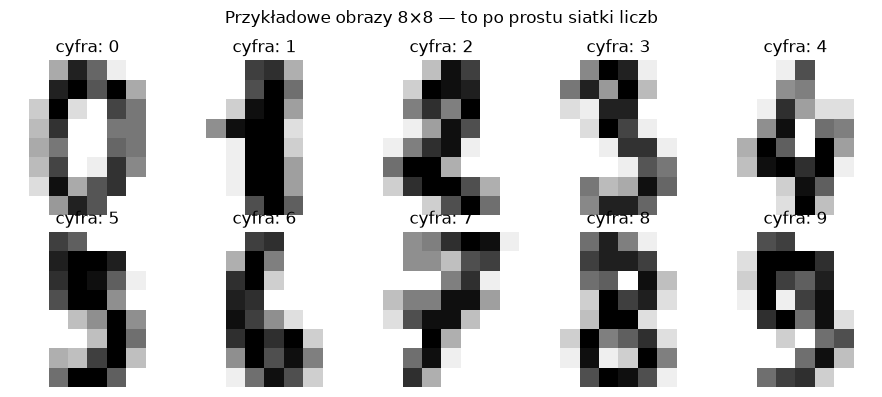

In [3]:

# Podgląd kilku obrazów wraz z etykietami
fig, osie = plt.subplots(2, 5, figsize=(9, 4))
for ax, obraz, etykieta in zip(osie.ravel(), digits.images, digits.target):
    ax.imshow(obraz, cmap="gray_r")
    ax.set_title(f"cyfra: {etykieta}")
    ax.axis("off")
plt.suptitle("Przykładowe obrazy 8×8 — to po prostu siatki liczb")
plt.tight_layout(); plt.show()

## 2. Przygotowanie danych

`digits.data` to gotowe, przygotowane obrazy (1797 × 64). Jak zwykle:
1. dzielimy na **trening** i **test** (test odkładamy - użyjemy go dopiero na końcu),
2. **standaryzujemy** cechy (SVM i k-NN tego potrzebują).

Dodatkowo tworzymy obiekt **walidacji krzyżowej** `cv`, którego użyjemy w wielu miejscach.

In [ ]:
from sklearn.model_selection import train_test_split

X_img = digits.data      # cechy: 64 piksele
y_img = digits.target    # cel: cyfra 0-9

# ZADANIE - podziel dane na trening/test, podaj random_state=67, rozmiar testu: 0.25


In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold

# Skalowanie i obiekt walidacji krzyżowej 
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("Trening:", X_train_s.shape, "| Test:", X_test_s.shape)

Trening: (1347, 64) | Test: (450, 64)


## 3. Punkt odniesienia (baseline)

Zanim ucieszymy się z wysokiej dokładności, sprawdźmy, ile daje **trywialny** model. `DummyClassifier(strategy="most_frequent")` zawsze zgaduje najczęstszą klasę. Przy 10 zrównoważonych cyfrach da ok. 10% - i **każdy sensowny model musi to wyraźnie przebić**.

https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score

dummy = DummyClassifier(strategy="most_frequent")
wynik_dummy = cross_val_score(dummy, X_train_s, y_train, cv=cv)
print("Baseline accuracy:", round(wynik_dummy.mean(), 3))


Baseline accuracy: 0.1


## 4. Znane metody na obrazach

Stosujemy do cyfr te same klasyfikatory co przy danych tabelarycznych. Schemat jest identyczny - `fit` na treningu, `predict` na teście. Zauważ, że problem ma **10 klas**, ale kod się nie zmienia:
`KNeighborsClassifier(n_neighbors=3)`
`SVC()`
`RandomForestClassifier(n_estimators=200, random_state=42)`
`LogisticRegression(max_iter=5000)`

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score

# ZADANIE - dla każdego modelu: utwórz model, naucz na (X_train_s, y_train),
#   przewidź dla X_test_s i policz accuracy


## 5. Dlaczego jeden podział to za mało - walidacja krzyżowa

Gdy oceniamy model na **jednym** podziale train/test, wynik zależy od szczęścia: inny losowy podział da trochę inny wynik.

**Pomysł walidacji krzyżowej (k-fold):** zamiast dzielić raz, dzielimy dane na `k` równych części (tzw. **foldów**). Potem `k` razy uczymy model - za każdym razem **jedna** część służy do sprawdzenia, a pozostałe do nauki. Na końcu **uśredniamy** `k` wyników.

Dla `k = 5` wygląda to tak (⬛ = walidacja, ⬜ = trening):

runda 1:  ⬛⬜⬜⬜⬜

runda 2:  ⬜⬛⬜⬜⬜

runda 3:  ⬜⬜⬛⬜⬜

runda 4:  ⬜⬜⬜⬛⬜

runda 5:  ⬜⬜⬜⬜⬛

Dzięki temu **każdy przykład raz jest sprawdzany**, a ocena jest **stabilniejsza** i mniej zależna od jednego losowania. Bonus: dostajemy nie tylko średnią, ale i **rozrzut** wyników.

## StratifiedKFold - foldy z zachowaniem proporcji klas

Dzieląc dane "po kolei", możemy przypadkiem zrobić fold tylko z jedną klasą. Gdyby np. 40% studentów zdało, to zwykły podział mógłby dać fold z samymi "zdał" - i ocena z takiego foldu byłaby bez sensu.

**StratifiedKFold** temu zapobiega: pilnuje, żeby **w każdym foldzie był taki sam udział klas jak w całym zbiorze**. Jeśli w danych jest 40% "zdał", to w każdym foldzie też będzie ~40% "zdał". Przy cyfrach 0-9 - w każdym foldzie znajdą się wszystkie dziesięć cyfr w podobnych proporcjach.

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html

Dane:      🔵🔵🔵🔵 ⚪⚪⚪⚪⚪⚪   (40% niebieskich)

Każdy fold odzwierciedla tę proporcję:

  fold 1: 🔵⚪   
  
  fold 2: 🔵⚪   ...   (~40% niebieskich w każdym)

To domyślny wybór dla klasyfikacji w scikit-learn (dlatego `cv=5` z klasyfikatorem i tak stratyfikuje). My zapisujemy `StratifiedKFold(...)` jawnie, żeby dołożyć `shuffle=True` (przetasowanie przed podziałem) i `random_state` (powtarzalny wynik). Krótko: **każdy fold to miniatura całego zbioru - dzięki temu ocena jest rzetelna.**

In [8]:
# Ocena modelu SVC przy użyciu walidacji krzyżowej (cross-validation)
wyniki_cv = cross_val_score(SVC(), X_train_s, y_train, cv=cv)
print("Wyniki z foldów:", np.round(wyniki_cv, 3))
print(f"Średnia = {wyniki_cv.mean():.3f}  (± {wyniki_cv.std():.3f})")


Wyniki z foldów: [0.989 0.974 0.981 0.978 0.978]
Średnia = 0.980  (± 0.005)


## 6. Uwaga na wyciek danych - `Pipeline`

Subtelność: powyżej skalowaliśmy **całość** przed walidacją, więc skaler "podejrzał" też foldy walidacyjne - to drobny **wyciek danych**. Poprawnie skaler należy dopasowywać **wewnątrz każdego foldu**, tylko na jego części treningowej.

### Czym jest Pipeline

`Pipeline` to **złożenie kilku kroków w jeden model**: najpierw przetwarzanie danych (np. skalowanie), a na końcu właściwy klasyfikator. Całość zachowuje się jak **jeden obiekt** - ma metody `.fit()` i `.predict()` jak zwykły model, tylko "w środku" dane przechodzą po kolei przez wszystkie kroki.

​`pipe = make_pipeline(StandardScaler(), SVC())`

To znaczy - najpierw przeskaluj cechy, potem podaj je do SVM - spięte w jedno.

### Co dzieje się przy `.fit()` i `.predict()`

- **`pipe.fit(X_train, y_train)`** - skaler *uczy się* średniej i odchylenia z `X_train`, przekształca dane, a przekształcone podaje do modelu, który się uczy.
- **`pipe.predict(X_nowe)`** - nowe dane są przekształcane **tymi samymi** liczbami (ze zbioru treningowego!) i dopiero potem trafiają do modelu.

Kluczowe: skaler zapamiętuje statystyki **tylko z treningu** i stosuje je wszędzie później. Nie musisz już ręcznie wołać `scaler.fit` / `scaler.transform` - Pipeline robi to w odpowiedniej kolejności za Ciebie.

### Dlaczego to rozwiązuje problem wycieku

Gdy dasz `Pipeline` do `cross_val_score`, biblioteka w **każdym foldzie** wykonuje cały pipeline od nowa: skaler uczy się **tylko na treningowej części tego foldu**, a fold walidacyjny jest przekształcany dopiero na końcu - nigdy nie "podglądany" przy liczeniu średniej. Wyciek znika automatycznie.

In [ ]:
from sklearn.pipeline import make_pipeline, Pipeline

# ŹLE - skaler widzi całość, w tym foldy walidacyjne (wyciek)
X_s = StandardScaler().fit_transform(X_train)
cross_val_score(SVC(), X_s, y_train, cv=cv)

# DOBRZE - skalowanie liczone osobno w każdym foldzie
cross_val_score(make_pipeline(StandardScaler(), SVC()), X_train, y_train, cv=cv)

### Kiedy stosować Pipeline

- **Zawsze, gdy masz jakieś przetwarzanie danych + model** i używasz walidacji krzyżowej lub `GridSearchCV` - to jedyny bezpieczny sposób, by uniknąć wycieku.
- Gdy chcesz **wygodnie przenosić model** (np. zapisać do gry) - jeden `Pipeline` niesie w sobie skalowanie *i* model, więc nie zapomnisz przekształcić danych.
- Gdy stroisz parametry - w `GridSearchCV` odwołujesz się do kroków po nazwie, np. `svc__C`, `svc__gamma` (przedrostek = nazwa kroku).

### Dwa sposoby tworzenia

W skrócie: **Pipeline skleja przetwarzanie i model w jedną całość, dba o właściwą kolejność i o to, by przekształcenia uczyły się tylko na danych treningowych — a przy walidacji krzyżowej robi to osobno w każdym foldzie.**

In [ ]:
# 1) make_pipeline - nazwy kroków nadawane automatycznie ("standardscaler", "svc")
pipe = make_pipeline(StandardScaler(), SVC())

# 2) Pipeline - sama nadajesz nazwy (przydatne przy GridSearchCV)
pipe = Pipeline([("scaler", StandardScaler()), ("svc", SVC())])

In [ ]:
# ZADANIE - zbuduj pipeline ze skalowaniem i SVM:
#   make_pipeline(StandardScaler(), SVC()) i oceń go walidacją krzyżową
#   na SUROWYCH danych treningowych (X_train, y_train, cv=cv).


## 7. Krzywa walidacji - jak `gamma` wpływa na SVM

`gamma` w jądrze RBF mówi, jak "lokalny" jest wpływ pojedynczego punktu. 

Zbyt małe `gamma` = model za prosty (**niedouczenie**).
Zbyt duże = granica "owija się" wokół pojedynczych pikseli (**przeuczenie**). 

`validation_curve` pokazuje wynik **treningowy** i **walidacyjny** dla wielu wartości `gamma` naraz - świetnie widać na tym oba zjawiska.

In [ ]:
from sklearn.model_selection import validation_curve

zakres_gamma = np.logspace(-4, 1, 6)   # od 0.0001 do 10

# Policz krzywą walidacji dla SVC po parametrze 'gamma'
tr_sc, va_sc = validation_curve(
    SVC(), X_train_s, y_train,
    param_name="gamma", param_range=zakres_gamma, cv=cv)


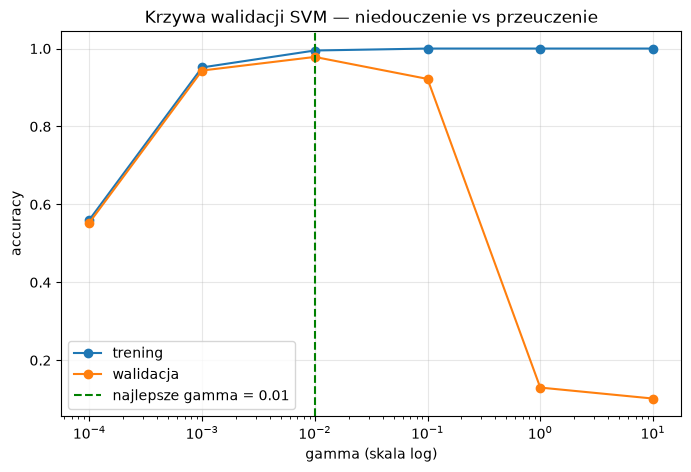

Zbyt duże gamma: trening ~1.0, walidacja spada = przeuczenie.


In [10]:

# Wykres krzywej walidacji
plt.figure(figsize=(8, 5))
plt.plot(zakres_gamma, tr_sc.mean(1), "o-", label="trening")
plt.plot(zakres_gamma, va_sc.mean(1), "o-", label="walidacja")
plt.xscale("log")
best_g = zakres_gamma[int(np.argmax(va_sc.mean(1)))]
plt.axvline(best_g, color="green", ls="--", label=f"najlepsze gamma = {best_g:g}")
plt.xlabel("gamma (skala log)"); plt.ylabel("accuracy")
plt.title("Krzywa walidacji SVM - niedouczenie vs przeuczenie")
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()
print("Zbyt duże gamma: trening ~1.0, walidacja spada = przeuczenie.")

## 8. Automatyczne strojenie - `GridSearchCV`

Zamiast dobierać parametry ręcznie, `GridSearchCV` sprawdzi **wszystkie kombinacje** z siatki, każdą oceniając walidacją krzyżową, i wybierze najlepszą. Używamy `Pipeline`, żeby skalowanie działo się poprawnie w każdym foldzie (klucze parametrów mają przedrostek kroku, np. `svc__C`).

In [ ]:
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([("scaler", StandardScaler()), ("svc", SVC())])
siatka = {"svc__C": [1, 10, 100], "svc__gamma": [0.0001, 0.001, 0.01]}

# ZADANIE - utwórz GridSearchCV(pipe, siatka, cv=cv) i naucz na (X_train, y_train)
# gs = 

# Wyniki strojenia 
# print("Najlepsze parametry:", gs.best_params_)
# print("Najlepszy wynik walidacji krzyżowej:", round(gs.best_score_, 4))


## 9. Ostateczna ocena na zbiorze testowym

Dopiero teraz sięgamy po **odłożony** zbiór testowy - dotykamy go raz. `GridSearchCV` po dopasowaniu automatycznie trenuje najlepszy model na całym treningu (`best_estimator_`), więc od razu go używamy.

In [14]:
# ZADANIE - użyj gs.best_estimator_, aby przewidzieć klasy dla X_test (zapisz do y_pred)
#   i wypisz accuracy na teście oraz porównaj z baseline.

# y_pred = 
# print("Accuracy na teście:", round(accuracy_score(y_test, y_pred), 4))
# print("Dla przypomnienia baseline:", round(wynik_dummy.mean(), 3))


Accuracy na teście: 0.9822
Dla przypomnienia baseline: 0.1


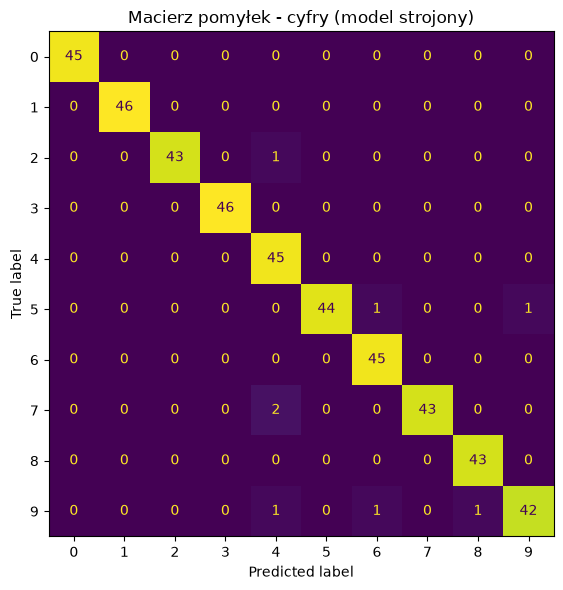

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        45
           1       1.00      1.00      1.00        46
           2       1.00      0.98      0.99        44
           3       1.00      1.00      1.00        46
           4       0.92      1.00      0.96        45
           5       1.00      0.96      0.98        46
           6       0.96      1.00      0.98        45
           7       1.00      0.96      0.98        45
           8       0.98      1.00      0.99        43
           9       0.98      0.93      0.95        45

    accuracy                           0.98       450
   macro avg       0.98      0.98      0.98       450
weighted avg       0.98      0.98      0.98       450



In [15]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

# Macierz pomyłek i raport 
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, colorbar=False)
ax.set_title("Macierz pomyłek - cyfry (najlepszy model)")
plt.tight_layout(); plt.show()

print(classification_report(y_test, y_pred))

## Które cyfry model pomylił?

Zobaczmy obrazy z testu, na których model się pomylił - często są to cyfry niejednoznaczne.

Liczba pomyłek na teście: 8


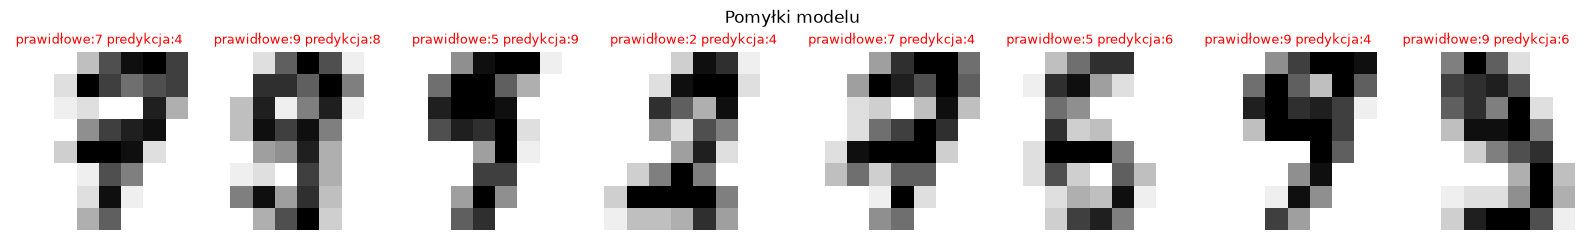

In [18]:

bledne = np.where(y_pred != y_test)[0]
print("Liczba pomyłek na teście:", len(bledne))

if len(bledne) > 0:
    ile = len(bledne)
    fig, osie = plt.subplots(1, ile, figsize=(2*ile, 2.4))
    osie = np.atleast_1d(osie)
    for ax, idx in zip(osie, bledne[:ile]):
        ax.imshow(X_test[idx].reshape(8, 8), cmap="gray_r")
        ax.set_title(f"prawidłowe:{y_test[idx]} predykcja:{y_pred[idx]}", color="red", fontsize=9)
        ax.axis("off")
    plt.suptitle("Pomyłki modelu")
    plt.tight_layout(); plt.show()

## Podsumowanie

- **Obraz to też dane tabelaryczne** - po rozprostowaniu do wektora pikseli te same klasyfikatory działają na obrazach (tu: cyfry 8×8 = 64 cechy).
- Baseline (`DummyClassifier`) mówi, od czego zaczynamy - model musi go wyraźnie bić.
- Jeden podział może być mylący - **walidacja krzyżowa** uśrednia wiele podziałów i daje stabilniejszą ocenę.
- `Pipeline` trzyma skalowanie wewnątrz foldów - chroni przed **wyciekiem danych**.
- **Krzywa walidacji** pokazuje niedouczenie/przeuczenie.
- `GridSearchCV` stroi parametry automatycznie.
- **Zbiór testowy** to jednorazowa, uczciwa ocena na koniec - nie używamy go do wyborów.